# Smallprob: four small generative models
Write a probability model once, then generate data, infer unknowns and draw its diagram.

Run from an installed project environment: `uv sync --extra vi --extra notebook`.
The examples use synthetic data. Exact results and approximate VI are labelled separately.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found.*", module="tqdm.auto")

import numpy as np
import torch
import matplotlib.pyplot as plt
from smallprob import model, Normal, HalfNormal, StudentT, HMM

plt.rcParams.update({
    "figure.figsize": (8, 3), "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#17464b", "#c67b51"]),
})

## 1. A Normal observation
An unknown mean, then one noisy observation. In Python, `Normal(mean, sd)` takes standard deviation. The diagram writes the mathematical variance explicitly.

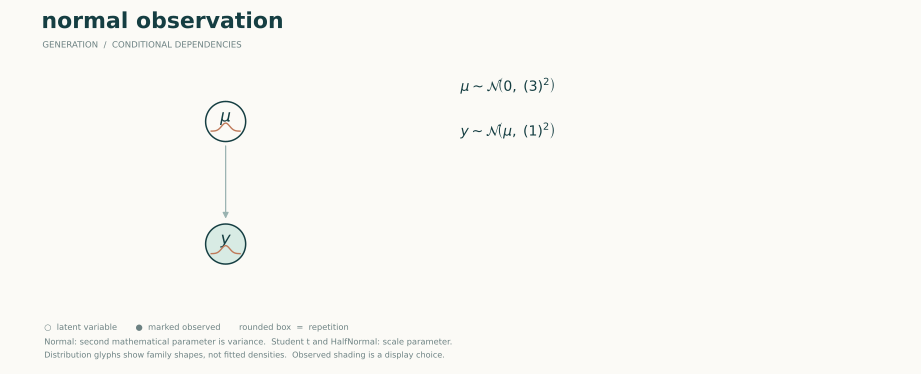

In [2]:
@model
def normal_observation():
    mu = Normal(0, 3)
    y = Normal(mu, 1)

simple = normal_observation()
simple.diagram(observed=["y"])

In [3]:
p = simple.infer(y=2.0)  # exact Gaussian inference
print(f"Posterior mean of mu: {p.mean('mu'):.3f}")
low, high = p.interval("mu")
print(f"95% marginal interval: [{low:.3f}, {high:.3f}]")
simple.math()

Posterior mean of mu: 1.800
95% marginal interval: [-0.059, 3.659]


ModelMath('normal_observation', equations=2)

The density is
$$p(y\mid\mu,\sigma)=\frac{1}{\sqrt{2\pi}\sigma}\exp\left[-\frac{(y-\mu)^2}{2\sigma^2}\right].$$

## 2. Linear regression, with either array library
A vector `x` creates a vector of observations. The two priors are shared by every observation. Display labels can use `m` and `b` while Python keeps readable variable names.

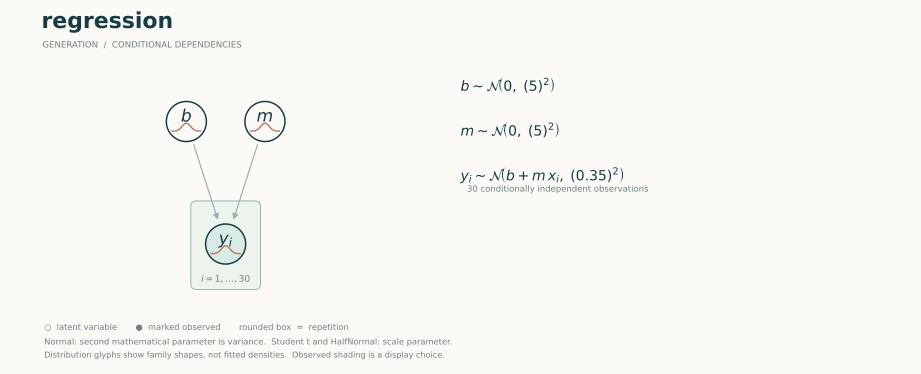

In [4]:
@model
def regression(x):
    intercept = Normal(0, 5)
    slope = Normal(0, 5)
    y = Normal(intercept + slope * x, 0.35)

x = np.linspace(-2, 2, 30)
line = regression(x)
data = line.simulate(seed=7, fixed={"intercept": 1.5, "slope": -0.8})
y = data["y"][0]
line.diagram(labels={"intercept": "b", "slope": "m"}, observed=["y"])

In [5]:
p_numpy = line.infer(y=y)
p_torch = regression(torch.tensor(x)).infer(y=torch.tensor(y))
print("NumPy slope:", p_numpy.mean("slope"))
print("Torch slope:", p_torch.mean("slope"))
print("Sample arrays:", type(p_numpy.sample(2)["y"]).__name__,
      type(p_torch.sample(2)["y"]).__name__)

NumPy slope: -0.8583117117584631
Torch slope: tensor(-0.8583, dtype=torch.float64)
Sample arrays: ndarray Tensor


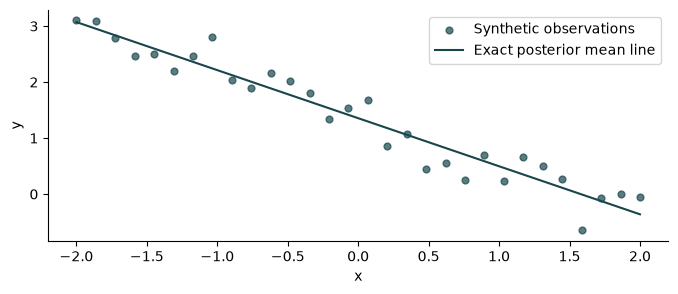

In [6]:
plt.scatter(x, y, s=24, alpha=0.7, label="Synthetic observations")
plt.plot(x, p_numpy.mean("intercept") + p_numpy.mean("slope") * x,
         label="Exact posterior mean line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

The next cell runs Gaussian conditioning on an available GPU, or CPU when neither accelerator is present. Computation and returned arrays use the selected device. Model tracing snapshots fixed inputs on the host. MPS uses float32.

In [7]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
x_device = torch.tensor(x, device=device, dtype=torch.float32)
y_device = torch.tensor(y, device=device, dtype=torch.float32)
p_device = regression(x_device).infer(y=y_device)
print("Device:", p_device.diagnostics["device"], "| slope:", float(p_device.mean("slope")))

Device: mps:0 | slope: -0.8583118915557861


## 3. Student's t for observations with outliers
Now the model uses mathematical names directly. A Student's t likelihood has heavier tails than a Normal. Here `df=4`; `scale` is **not** the standard deviation. We also learn the positive noise scale.

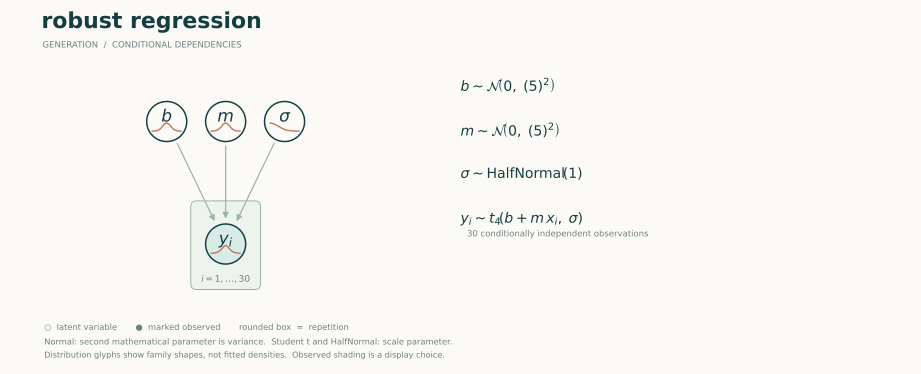

In [8]:
@model
def robust_regression(x):
    b = Normal(0, 5)
    m = Normal(0, 5)
    sigma = HalfNormal(1)
    y = StudentT(df=4, loc=b + m * x, scale=sigma)

robust = robust_regression(x)
robust.diagram(observed=["y"])

In [9]:
y_outliers = y.copy()
y_outliers[[5, 24]] += [3.0, -3.0]  # two deliberately added outliers
p_robust = robust.infer(y=y_outliers, method="vi", seed=7)
p_normal = line.infer(y=y_outliers)
print("Approximate VI slope:", p_robust.mean("m"))
print("95% guide interval:", p_robust.interval("m"))
print("Learned Student t scale:", p_robust.mean("sigma"))

Approximate VI slope: -0.8771833468713156
95% guide interval: (-0.9896255166971057, -0.7647411770455255)
Learned Student t scale: 0.3346281607087577


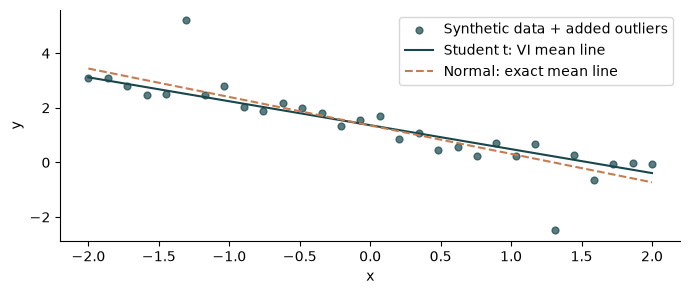

In [10]:
plt.scatter(x, y_outliers, s=24, alpha=0.7, label="Synthetic data + added outliers")
plt.plot(x, p_robust.mean("b") + p_robust.mean("m") * x, label="Student t: VI mean line")
plt.plot(x, p_normal.mean("intercept") + p_normal.mean("slope") * x,
         linestyle="--", label="Normal: exact mean line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

For location $\mu$, scale $s$ and degrees of freedom $\nu$:
$$p(y\mid\nu,\mu,s)=\frac{\Gamma((\nu+1)/2)}{\Gamma(\nu/2)\sqrt{\nu\pi}\,s}\left(1+\frac{(y-\mu)^2}{\nu s^2}\right)^{-(\nu+1)/2}.$$
For $\nu>2$, the variance is $s^2\nu/(\nu-2)$. VI intervals describe the learned approximation, not exact posterior uncertainty. The fitted lines illustrate this fixed dataset, not a general robustness guarantee.

## 4. A hidden Markov model
Each hidden state depends on the previous state, and each observation depends on its current state. Specify the model directly with `HMM`: no loop, append or decorator. Rows of the transition matrix correspond to the current state; columns to the next state. Parameters are supplied here; state inference is exact and uses NumPy on CPU. Names label states 0 and 1.

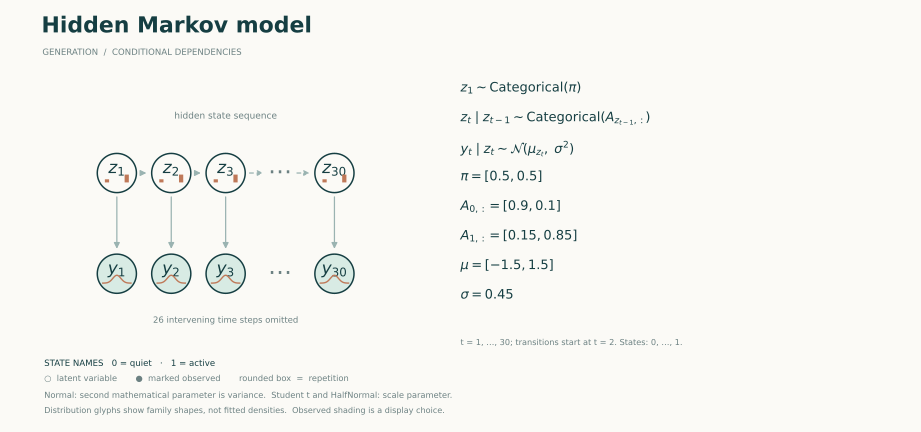

In [11]:
chain = HMM(
    states=["quiet", "active"],
    initial=[0.5, 0.5],
    transition=[[0.9, 0.1], [0.15, 0.85]],
    emissions=Normal([-1.5, 1.5], 0.45),
    steps=30,
)
chain.diagram(observed=["y"])

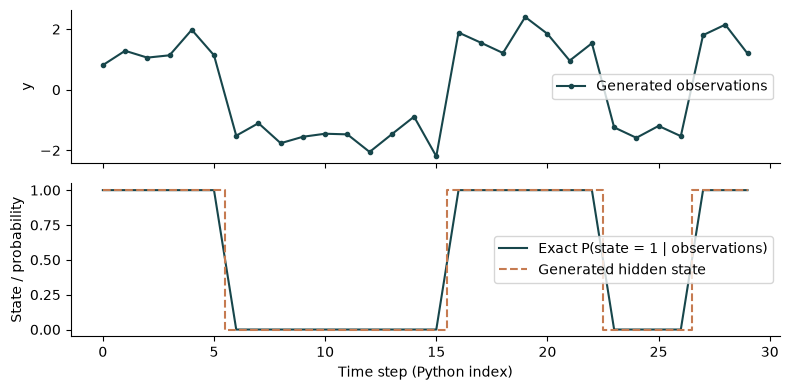

In [12]:
sequence = chain.simulate(seed=7)
states = chain.infer(y=sequence["y"][0])
fig, axes = plt.subplots(2, 1, figsize=(8, 4), sharex=True)
axes[0].plot(sequence["y"][0], ".-", label="Generated observations")
axes[0].set_ylabel("y"); axes[0].legend()
axes[1].plot(states.probabilities("z")[:, 1], label="Exact P(state = 1 | observations)")
axes[1].step(range(30), sequence["z"][0], where="mid", linestyle="--", label="Generated hidden state")
axes[1].set(xlabel="Time step (Python index)", ylabel="State / probability", ylim=(-0.05, 1.05))
axes[1].legend(); plt.tight_layout(); plt.show()

## Export a diagram
SVG keeps equations, arrows and distribution glyphs sharp. Display labels do not rename variables used by inference. Glyphs identify distribution families; they are not fitted density estimates.

In [13]:
robust.diagram(observed=["y"]).save("outputs/notebook-robust-model.svg")
print("Saved outputs/notebook-robust-model.svg")

Saved outputs/notebook-robust-model.svg
